# Three-layer daily snow storage

Estimate daily snow water equivalent (SWE) from the cleaned station temperatures and shared Nikkaluokta precipitation. This notebook reads through `load_cleaned_data()` and leaves all cleaned files unchanged.

| Layer | Elevation (m) | Temperature | Area weight |
|---|---:|---|---:|
| Nikkaluokta | 466.765 | Cleaned candidate, observed where available | 1/3 |
| Middle | 805.209 | Daily average of both station temperatures | 1/3 |
| Tarfala | 1143.653 | Cleaned candidate, observed where available | 1/3 |

The middle temperature assumes a linear profile in elevation and retains inversions. Each layer receives the **full precipitation depth**. Combined SWE is the mean of the three independent stores, in **mm of water equivalent**, not physical snow depth.

All snow at ≤−1°C, all rain at ≥+1°C, and a linear snow/rain mix between. Potential melt is `3 × max(T, 0)` mm/day; actual melt is capped by available snow, including today's snowfall:

`SWE_today = SWE_yesterday + snowfall_today − melt_today`

Storage carries continuously without annual resets. These are uncalibrated seasonal snow estimates; the model omits glacier processes, sublimation, refreezing, liquid-water retention, and spatial precipitation differences.

In [1]:
%matplotlib inline
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display

from kalix.cleanup import load_cleaned_data
from kalix.snow import FLUXES, LAYERS, analyze_cleaned_snow

cleaned = load_cleaned_data()
snow = analyze_cleaned_snow(cleaned)

# Check the full record rather than silently dropping unavailable days.
assert snow.index.equals(pd.date_range("1995-11-22", "2026-06-30", name=cleaned.index.name))
model_columns = [
    *(f"{layer}_temperature_c" for layer in LAYERS),
    *(f"{zone}_{flux}_mm" for zone in (*LAYERS, "combined") for flux in FLUXES),
    "precipitation_used_mm",
    "initialization_max_difference_mm",
]
assert np.isfinite(snow[model_columns].to_numpy(dtype=float)).all()
assert snow.precipitation_assumed_zero.sum() == 30
assert snow.loc["1999-06-01":"1999-06-30", "precipitation_assumed_zero"].all()
assert (snow.filter(regex="_swe_mm$") >= 0).all().all()

print(
    f"{snow.index[0]:%Y-%m-%d} to {snow.index[-1]:%Y-%m-%d}: {len(snow):,} complete daily results"
)
print("First initialization convergence:", snow.attrs["initialization"]["first_convergence_date"])
display(
    pd.DataFrame(
        {
            "layer": LAYERS,
            "elevation_m": [
                snow.attrs["snow_model"]["layer_elevations_m"][layer] for layer in LAYERS
            ],
            "area_weight": [1 / 3] * 3,
        }
    )
)
display(
    pd.Series(
        {
            "Assumed-zero precipitation days": int(snow.precipitation_assumed_zero.sum()),
            "Nikkaluokta temperature estimates": int(snow.nikkaluokta_temperature_imputed.sum()),
            "Tarfala temperature estimates": int(snow.tarfala_temperature_imputed.sum()),
            "Initialization-sensitive days": int((~snow.initialization_converged).sum()),
        },
        name="Days",
    )
)

1995-11-22 to 2026-06-30: 11,179 complete daily results
First initialization convergence: 1996-08-05


,layer,elevation_m,area_weight
0,nikkaluokta,466.765,0.333333
1,middle,805.209,0.333333
2,tarfala,1143.653,0.333333


Assumed-zero precipitation days       30
Nikkaluokta temperature estimates    100
Tarfala temperature estimates        640
Initialization-sensitive days        257
Name: Days, dtype: int64

## Assumptions and flags

- **Orange shading:** precipitation is missing during June 1999 and is assumed to be **0 mm for this calculation**. `precipitation_mm` retains the original missing readings; `precipitation_used_mm` contains the calculation input. Actual observed zero precipitation is not flagged.
- **Grey shading:** the zero-start and 1,000 mm-start runs differ by more than 0.00000001 mm in at least one layer. The lower panel shows the maximum difference across all three layers. Convergence only concerns these starting states.
- **Cross markers on station temperature curves:** cleaned estimates used instead of missing observations.

Both initialization runs use the same assumed June precipitation. **Convergence does not resolve uncertainty from that assumption**, whose effects can persist after June 1999. Neither the zero start in November 1995 nor convergence establishes observed snow-free conditions.

## Select a date range

Edit `VIEW_START` and `VIEW_END`, then rerun the **Selected interval** cell below. Use `None` for either boundary to include the full available range. The full simulation always runs first, so selecting a view never restarts snow storage.

The table shows at most `TABLE_DAYS` daily rows, starting at `TABLE_START`, or at the beginning of the selected view when it is `None`. All daily values remain available in `snow` for further analysis.

Examples: `1999-05-15` to `1999-07-15` for the precipitation assumption, or `2024-09-01` to `2025-08-31` for a recent snow season.

In [2]:
VIEW_START = None
VIEW_END = None
TABLE_START = None
TABLE_DAYS = 31

In [3]:
COLORS = {"nikkaluokta": "#2563eb", "middle": "#9333ea", "tarfala": "#15803d"}


def shade_periods(ax, frame):
    """Shade contiguous flagged days, including the entire last day."""
    for mask, color, label in (
        (frame.precipitation_assumed_zero, "#fb923c", "Precipitation assumed zero"),
        (~frame.initialization_converged, "#94a3b8", "Initialization-sensitive"),
    ):
        groups = mask.ne(mask.shift()).cumsum()
        first = True
        for _, block in frame.loc[mask].groupby(groups[mask]):
            ax.axvspan(
                block.index[0],
                block.index[-1] + pd.Timedelta(days=1),
                color=color,
                alpha=0.18,
                label=label if first else None,
            )
            first = False


def review_snow(start=None, end=None, table_start=None, table_days=31):
    """Inspect stored results without rerunning or resetting the model."""
    frame = snow.loc[start:end]
    if frame.empty:
        raise ValueError("The selected dates contain no results.")
    if not isinstance(table_days, int) or table_days <= 0:
        raise ValueError("TABLE_DAYS must be a positive integer.")
    table = frame.loc[table_start:].head(table_days)
    if table.empty:
        raise ValueError("TABLE_START is outside the selected date range.")

    fig, axes = plt.subplots(3, 1, figsize=(16, 10), sharex=True, layout="constrained")
    for layer in LAYERS:
        axes[0].plot(
            frame.index,
            frame[f"{layer}_temperature_c"],
            color=COLORS[layer],
            linewidth=0.8,
            label=layer.title(),
        )
        if layer != "middle":
            inserted = frame[f"{layer}_temperature_imputed"]
            axes[0].scatter(
                frame.index[inserted],
                frame.loc[inserted, f"{layer}_temperature_c"],
                marker="x",
                color=COLORS[layer],
                s=24,
                label=f"{layer.title()} estimated",
                zorder=4,
            )
        axes[1].plot(
            frame.index,
            frame[f"{layer}_swe_mm"],
            color=COLORS[layer],
            linewidth=1,
            label=layer.title(),
        )
    axes[0].axhline(0, color="#64748b", linestyle=":", linewidth=0.8)
    axes[0].set_ylabel("Daily temperature (°C)")
    axes[1].plot(
        frame.index,
        frame.combined_swe_mm,
        color="#111827",
        linewidth=1.6,
        label="Combined (equal-area mean)",
    )
    axes[1].set_ylabel("End-of-day SWE (mm)")
    axes[2].plot(
        frame.index,
        frame.initialization_max_difference_mm,
        color="#475569",
        linewidth=1,
        label="Maximum layer difference",
    )
    axes[2].set_ylabel("Initial-state difference (mm)")
    axes[2].set_xlabel("Date")
    for ax in axes:
        shade_periods(ax, frame)
        ax.grid(alpha=0.2)
        ax.legend(loc="upper left", ncol=3, fontsize=8)
    locator = mdates.AutoDateLocator(minticks=4, maxticks=10)
    axes[-1].xaxis.set_major_locator(locator)
    axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    axes[-1].set_xlim(frame.index[0], frame.index[-1] + pd.Timedelta(days=1))
    fig.suptitle(
        f"Three-layer snow storage: {frame.index[0]:%Y-%m-%d} to {frame.index[-1]:%Y-%m-%d}"
    )
    plt.show()

    print(
        f"Selected view: {len(frame):,} days; table: {len(table)} days. "
        "All daily results are in the snow dataframe."
    )
    print("Orange table rows: precipitation assumed zero. Grey rows: initialization-sensitive.")
    print("Scroll horizontally to inspect every layer's snowfall, rain, melt, and SWE.")

    def highlight(row):
        color = (
            "#ffedd5"
            if row.precipitation_assumed_zero
            else "#e2e8f0"
            if not row.initialization_converged
            else ""
        )
        return [f"background-color: {color}" if color else "" for _ in row]

    styled = table.style.format(precision=3, na_rep="missing").apply(highlight, axis=1)
    display(HTML('<div style="overflow:auto;max-height:600px">' + styled.to_html() + "</div>"))
    return frame

## Selected interval

The table includes all three temperatures, each layer's snowfall/rain/melt/SWE, combined fluxes and SWE, original and used precipitation, temperature-imputation flags, and initialization diagnostics.

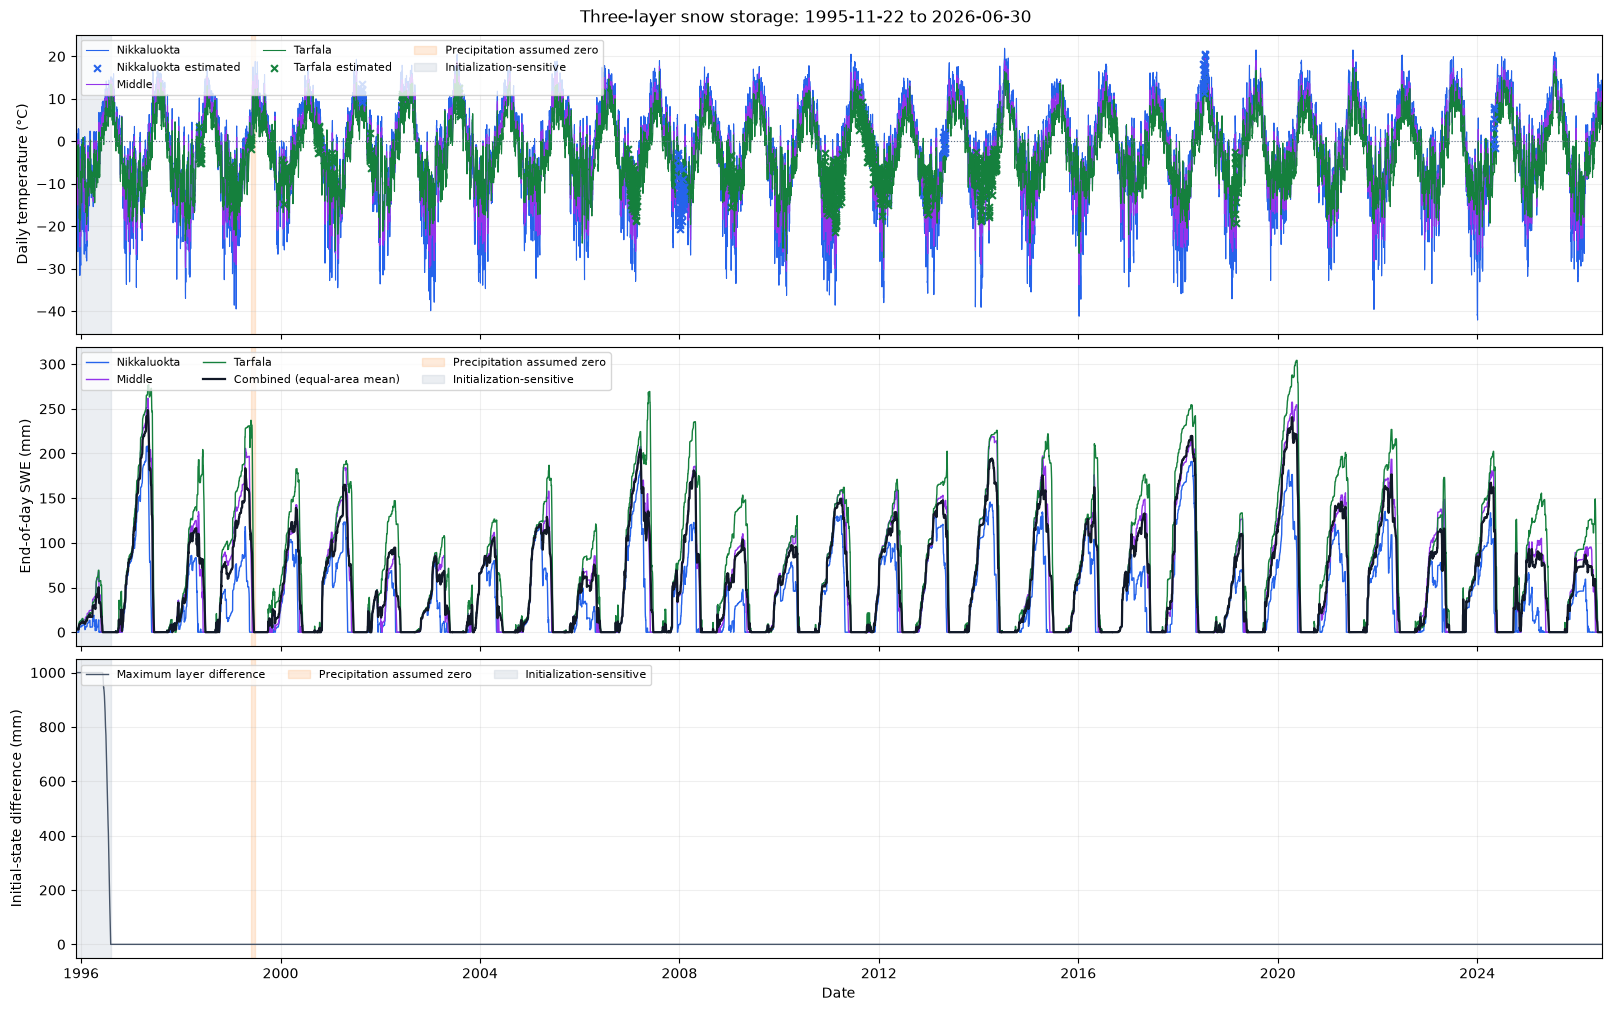

Selected view: 11,179 days; table: 31 days. All daily results are in the snow dataframe.
Orange table rows: precipitation assumed zero. Grey rows: initialization-sensitive.
Scroll horizontally to inspect every layer's snowfall, rain, melt, and SWE.


,nikkaluokta_temperature_c,middle_temperature_c,tarfala_temperature_c,nikkaluokta_snowfall_mm,nikkaluokta_rain_mm,nikkaluokta_melt_mm,nikkaluokta_swe_mm,middle_snowfall_mm,middle_rain_mm,middle_melt_mm,middle_swe_mm,tarfala_snowfall_mm,tarfala_rain_mm,tarfala_melt_mm,tarfala_swe_mm,combined_snowfall_mm,combined_rain_mm,combined_melt_mm,combined_swe_mm,precipitation_mm,precipitation_used_mm,precipitation_assumed_zero,nikkaluokta_temperature_imputed,tarfala_temperature_imputed,initialization_max_difference_mm,initialization_converged
date,,,,,,,,,,,,,,,,,,,,,,,,,,
1995-11-22 00:00:00,-10.100,-6.850,-3.600,0.800,0.000,0.000,0.800,0.800,0.000,0.000,0.800,0.800,0.000,0.000,0.800,0.800,0.000,0.000,0.800,0.800,0.800,False,False,False,1000.000,False
1995-11-23 00:00:00,-6.300,-3.700,-1.100,1.400,0.000,0.000,2.200,1.400,0.000,0.000,2.200,1.400,0.000,0.000,2.200,1.400,0.000,0.000,2.200,1.400,1.400,False,False,False,1000.000,False
1995-11-24 00:00:00,-2.800,-5.050,-7.300,1.000,0.000,0.000,3.200,1.000,0.000,0.000,3.200,1.000,0.000,0.000,3.200,1.000,0.000,0.000,3.200,1.000,1.000,False,False,False,1000.000,False
1995-11-25 00:00:00,-24.500,-20.650,-16.800,1.000,0.000,0.000,4.200,1.000,0.000,0.000,4.200,1.000,0.000,0.000,4.200,1.000,0.000,0.000,4.200,1.000,1.000,False,False,False,1000.000,False
1995-11-26 00:00:00,-34.800,-26.600,-18.400,0.100,0.000,0.000,4.300,0.100,0.000,0.000,4.300,0.100,0.000,0.000,4.300,0.100,0.000,0.000,4.300,0.100,0.100,False,False,False,1000.000,False
1995-11-27 00:00:00,-34.800,-25.200,-15.600,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,False,False,False,1000.000,False
1995-11-28 00:00:00,-30.100,-20.200,-10.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,False,False,False,1000.000,False
1995-11-29 00:00:00,-9.200,-7.450,-5.700,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,False,False,False,1000.000,False
1995-11-30 00:00:00,1.900,-0.350,-2.600,0.000,0.000,4.300,0.000,0.000,0.000,0.000,4.300,0.000,0.000,0.000,4.300,0.000,0.000,1.433,2.867,0.000,0.000,False,False,False,1000.000,False


In [4]:
selected = review_snow(VIEW_START, VIEW_END, TABLE_START, TABLE_DAYS)

## June 1999 assumption in detail

This view makes the missing precipitation explicit, including its daily forcing and the snow stores carried in from May. Snow storage is not reset at either end of the gap.

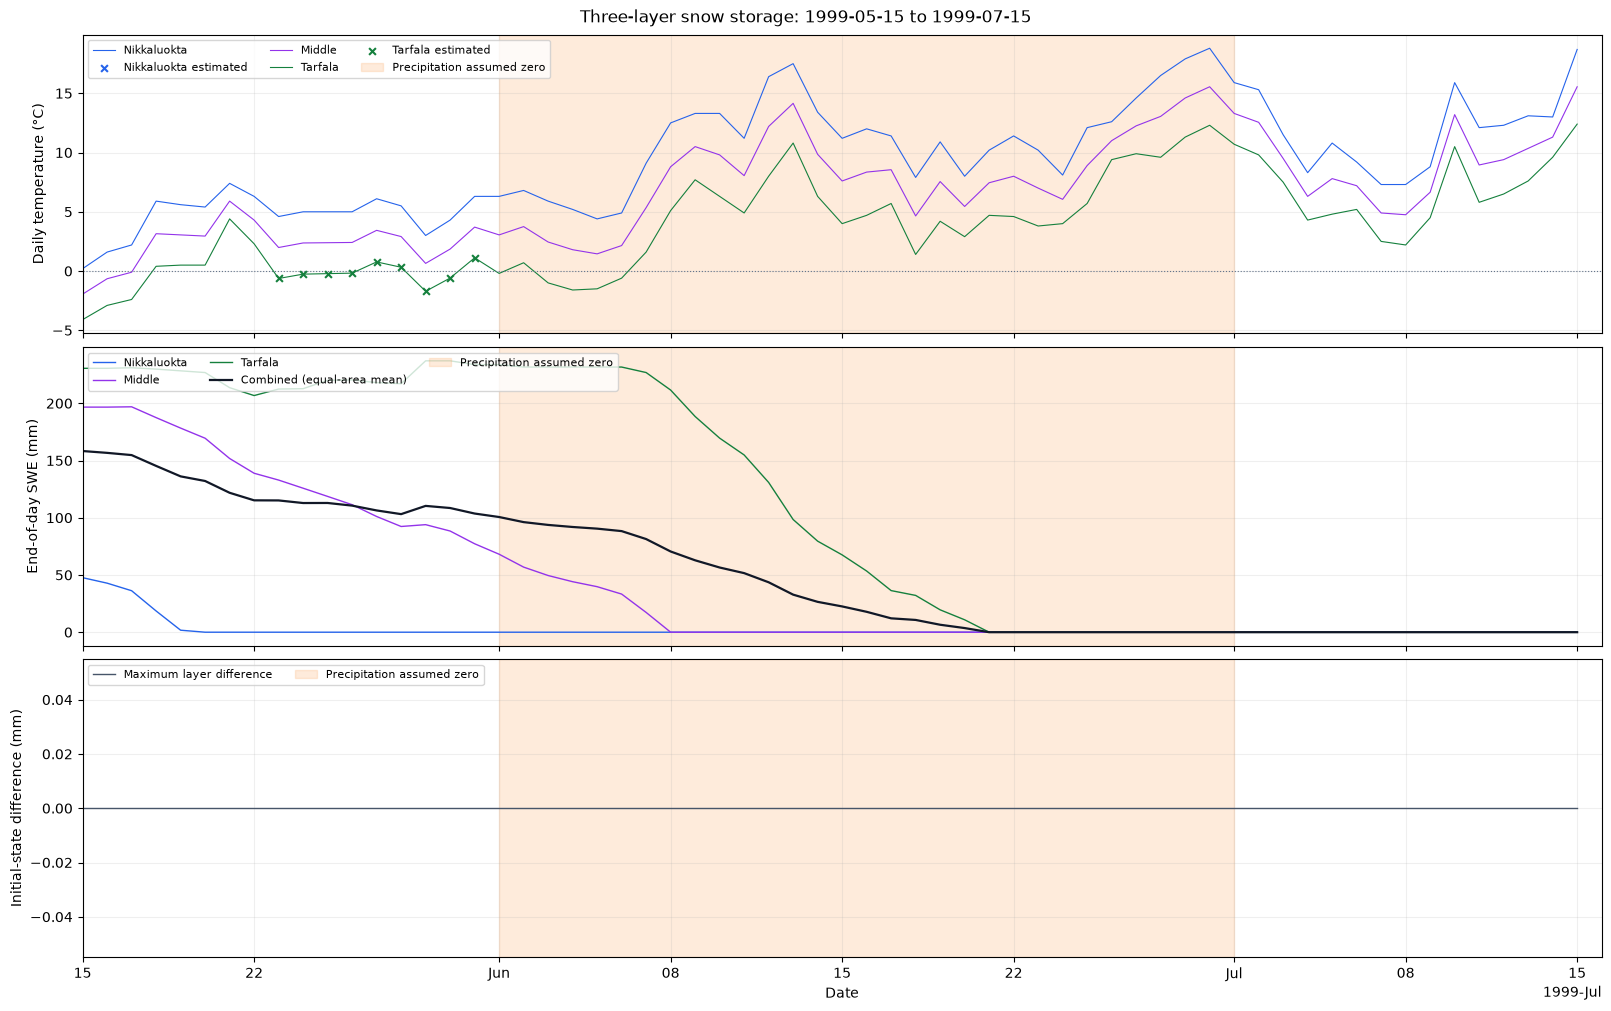

Selected view: 62 days; table: 30 days. All daily results are in the snow dataframe.
Orange table rows: precipitation assumed zero. Grey rows: initialization-sensitive.
Scroll horizontally to inspect every layer's snowfall, rain, melt, and SWE.


,nikkaluokta_temperature_c,middle_temperature_c,tarfala_temperature_c,nikkaluokta_snowfall_mm,nikkaluokta_rain_mm,nikkaluokta_melt_mm,nikkaluokta_swe_mm,middle_snowfall_mm,middle_rain_mm,middle_melt_mm,middle_swe_mm,tarfala_snowfall_mm,tarfala_rain_mm,tarfala_melt_mm,tarfala_swe_mm,combined_snowfall_mm,combined_rain_mm,combined_melt_mm,combined_swe_mm,precipitation_mm,precipitation_used_mm,precipitation_assumed_zero,nikkaluokta_temperature_imputed,tarfala_temperature_imputed,initialization_max_difference_mm,initialization_converged
date,,,,,,,,,,,,,,,,,,,,,,,,,,
1999-06-01 00:00:00,6.300,3.050,-0.200,0.000,0.000,0.000,0.000,0.000,0.000,9.150,68.120,0.000,0.000,0.000,233.747,0.000,0.000,3.050,100.622,missing,0.000,True,False,False,0.000,True
1999-06-02 00:00:00,6.800,3.750,0.700,0.000,0.000,0.000,0.000,0.000,0.000,11.250,56.870,0.000,0.000,2.100,231.647,0.000,0.000,4.450,96.172,missing,0.000,True,False,False,0.000,True
1999-06-03 00:00:00,5.900,2.450,-1.000,0.000,0.000,0.000,0.000,0.000,0.000,7.350,49.520,0.000,0.000,0.000,231.647,0.000,0.000,2.450,93.722,missing,0.000,True,False,False,0.000,True
1999-06-04 00:00:00,5.200,1.800,-1.600,0.000,0.000,0.000,0.000,0.000,0.000,5.400,44.120,0.000,0.000,0.000,231.647,0.000,0.000,1.800,91.922,missing,0.000,True,False,False,0.000,True
1999-06-05 00:00:00,4.400,1.450,-1.500,0.000,0.000,0.000,0.000,0.000,0.000,4.350,39.770,0.000,0.000,0.000,231.647,0.000,0.000,1.450,90.472,missing,0.000,True,False,False,0.000,True
1999-06-06 00:00:00,4.900,2.150,-0.600,0.000,0.000,0.000,0.000,0.000,0.000,6.450,33.320,0.000,0.000,0.000,231.647,0.000,0.000,2.150,88.322,missing,0.000,True,False,False,0.000,True
1999-06-07 00:00:00,9.100,5.350,1.600,0.000,0.000,0.000,0.000,0.000,0.000,16.050,17.270,0.000,0.000,4.800,226.847,0.000,0.000,6.950,81.372,missing,0.000,True,False,False,0.000,True
1999-06-08 00:00:00,12.500,8.800,5.100,0.000,0.000,0.000,0.000,0.000,0.000,17.270,0.000,0.000,0.000,15.300,211.547,0.000,0.000,10.857,70.516,missing,0.000,True,False,False,0.000,True
1999-06-09 00:00:00,13.300,10.500,7.700,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,23.100,188.447,0.000,0.000,7.700,62.816,missing,0.000,True,False,False,0.000,True


In [5]:
gap_view = review_snow("1999-05-15", "1999-07-15", table_start="1999-06-01", table_days=30)

## Recorded model assumptions

These dictionaries accompany `snow`. They record parameters, layer weights and elevations, the simulation period, forcing columns, precipitation policy, and initialization check. The original cleaned files and their provenance remain unchanged.

In [6]:
display(snow.attrs)

{'snow_model': {'model': 'three_equal_area_layers',
  'parameters': {'degree_day_factor': 3.0,
   'snow_temperature_c': -1.0,
   'rain_temperature_c': 1.0,
   'melt_temperature_c': 0.0},
  'initial_swe_mm': [0.0, 0.0, 0.0],
  'layer_order': ['nikkaluokta', 'middle', 'tarfala'],
  'layer_elevations_m': {'nikkaluokta': 466.765,
   'middle': 805.209,
   'tarfala': 1143.653},
  'area_weights': {'nikkaluokta': 0.3333333333333333,
   'middle': 0.3333333333333333,
   'tarfala': 0.3333333333333333},
  'middle_temperature': 'Daily arithmetic mean; linear interpolation in elevation.',
  'units': 'mm water equivalent; fluxes are daily amounts, SWE is end-of-day storage',
  'precipitation': 'Same full Nikkaluokta precipitation depth applied to each layer.',
  'alignment': 'Source daily labels; observation windows have not been synchronized.',
  'interpretation': 'Uncalibrated seasonal snow-storage proxy, not observed catchment SWE.'},
 'forcing_provenance': {'temperature_columns': ['nikkaluokta_te